In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("House Price.csv")

In [4]:
df.head()

,POSTED_BY,UNDER_CONSTRUCTION,RERA,BHK_NO.,BHK_OR_RK,SQUARE_FT,READY_TO_MOVE,RESALE,ADDRESS,LONGITUDE,LATITUDE,TARGET(PRICE_IN_LACS)
0,Owner,0,0,2,BHK,1300.236407,1,1,"Ksfc Layout,Bangalore",12.969910,77.597960,55.0
1,Dealer,0,0,2,BHK,1275.000000,1,1,"Vishweshwara Nagar,Mysore",12.274538,76.644605,51.0
2,Owner,0,0,2,BHK,933.159722,1,1,"Jigani,Bangalore",12.778033,77.632191,43.0
3,Owner,0,1,2,BHK,929.921143,1,1,"Sector-1 Vaishali,Ghaziabad",28.642300,77.344500,62.5
4,Dealer,1,0,2,BHK,999.009247,0,1,"New Town,Kolkata",22.592200,88.484911,60.5


In [5]:
df.shape

(29451, 12)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29451 entries, 0 to 29450
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   POSTED_BY              29451 non-null  str    
 1   UNDER_CONSTRUCTION     29451 non-null  int64  
 2   RERA                   29451 non-null  int64  
 3   BHK_NO.                29451 non-null  int64  
 4   BHK_OR_RK              29451 non-null  str    
 5   SQUARE_FT              29451 non-null  float64
 6   READY_TO_MOVE          29451 non-null  int64  
 7   RESALE                 29451 non-null  int64  
 8   ADDRESS                29451 non-null  str    
 9   LONGITUDE              29451 non-null  float64
 10  LATITUDE               29451 non-null  float64
 11  TARGET(PRICE_IN_LACS)  29451 non-null  float64
dtypes: float64(4), int64(5), str(3)
memory usage: 3.5 MB


In [7]:
df.describe()

,UNDER_CONSTRUCTION,RERA,BHK_NO.,SQUARE_FT,READY_TO_MOVE,RESALE,LONGITUDE,LATITUDE,TARGET(PRICE_IN_LACS)
count,29451.000000,29451.000000,29451.000000,2.945100e+04,29451.000000,29451.000000,29451.000000,29451.000000,29451.000000
mean,0.179756,0.317918,2.392279,1.980217e+04,0.820244,0.929578,21.300255,76.837695,142.898746
std,0.383991,0.465675,0.879091,1.901335e+06,0.383991,0.255861,6.205306,10.557747,656.880713
min,0.000000,0.000000,1.000000,3.000000e+00,0.000000,0.000000,-37.713008,-121.761248,0.250000
25%,0.000000,0.000000,2.000000,9.000211e+02,1.000000,1.000000,18.452663,73.798100,38.000000
50%,0.000000,0.000000,2.000000,1.175057e+03,1.000000,1.000000,20.750000,77.324137,62.000000
75%,0.000000,1.000000,3.000000,1.550688e+03,1.000000,1.000000,26.900926,77.828740,100.000000
max,1.000000,1.000000,20.000000,2.545455e+08,1.000000,1.000000,59.912884,152.962676,30000.000000


In [8]:
df.describe(include="object")

,POSTED_BY,BHK_OR_RK,ADDRESS
count,29451,29451,29451
unique,3,2,6899
top,Dealer,BHK,"Zirakpur,Chandigarh"
freq,18291,29427,509


In [9]:
df.columns

Index(['POSTED_BY', 'UNDER_CONSTRUCTION', 'RERA', 'BHK_NO.', 'BHK_OR_RK',
       'SQUARE_FT', 'READY_TO_MOVE', 'RESALE', 'ADDRESS', 'LONGITUDE',
       'LATITUDE', 'TARGET(PRICE_IN_LACS)'],
      dtype='str')

In [10]:
df.isnull().sum()

POSTED_BY                0
UNDER_CONSTRUCTION       0
RERA                     0
BHK_NO.                  0
BHK_OR_RK                0
SQUARE_FT                0
READY_TO_MOVE            0
RESALE                   0
ADDRESS                  0
LONGITUDE                0
LATITUDE                 0
TARGET(PRICE_IN_LACS)    0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(401)

In [12]:
cols = [
    'POSTED_BY',
    'UNDER_CONSTRUCTION',
    'RERA',
    'BHK_NO.',
    'BHK_OR_RK',
    'READY_TO_MOVE',
    'RESALE'
]

for col in cols:
    print(f"\n{col}")
    print(df[col].value_counts())


POSTED_BY
POSTED_BY
Dealer     18291
Owner      10538
Builder      622
Name: count, dtype: int64

UNDER_CONSTRUCTION
UNDER_CONSTRUCTION
0    24157
1     5294
Name: count, dtype: int64

RERA
RERA
0    20088
1     9363
Name: count, dtype: int64

BHK_NO.
BHK_NO.
2     13324
3     10546
1      3574
4      1723
5       190
6        52
7        11
8        10
20        4
10        4
15        4
12        3
9         3
13        1
17        1
11        1
Name: count, dtype: int64

BHK_OR_RK
BHK_OR_RK
BHK    29427
RK        24
Name: count, dtype: int64

READY_TO_MOVE
READY_TO_MOVE
1    24157
0     5294
Name: count, dtype: int64

RESALE
RESALE
1    27377
0     2074
Name: count, dtype: int64


In [13]:
# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Reset index
df.reset_index(drop=True, inplace=True)

# Verify
print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())

Dataset shape after removing duplicates: (29050, 12)
Remaining duplicates: 0


In [14]:
pd.crosstab(df['UNDER_CONSTRUCTION'], df['READY_TO_MOVE'])

READY_TO_MOVE,0,1
UNDER_CONSTRUCTION,,
0,0,23851
1,5199,0


In [15]:
(df['UNDER_CONSTRUCTION'] + df['READY_TO_MOVE']).value_counts()

1    29050
Name: count, dtype: int64

In [16]:
# Check number of unique values in each column
df.nunique().sort_values()

UNDER_CONSTRUCTION           2
RERA                         2
READY_TO_MOVE                2
BHK_OR_RK                    2
RESALE                       2
POSTED_BY                    3
BHK_NO.                     16
TARGET(PRICE_IN_LACS)     1172
LATITUDE                  4078
LONGITUDE                 4087
ADDRESS                   6899
SQUARE_FT                19561
dtype: int64

In [17]:
# Inspect location variables
df[['ADDRESS', 'LONGITUDE', 'LATITUDE']].head(20)

,ADDRESS,LONGITUDE,LATITUDE
0,"Ksfc Layout,Bangalore",12.969910,77.597960
1,"Vishweshwara Nagar,Mysore",12.274538,76.644605
2,"Jigani,Bangalore",12.778033,77.632191
3,"Sector-1 Vaishali,Ghaziabad",28.642300,77.344500
4,"New Town,Kolkata",22.592200,88.484911
5,"South Chittoor,Kochi",10.033280,76.282571
6,"Sodala,Jaipur",26.916347,75.795600
7,"Kharar,Mohali",30.740000,76.650000
8,"Bileshivale,Bangalore",13.054202,77.674002
9,"Chromepet,Chennai",12.951610,80.140970


In [18]:
# Top 20 most frequent addresses
df['ADDRESS'].value_counts().head(20)

ADDRESS
Zirakpur,Chandigarh                   474
Whitefield,Bangalore                  222
Raj Nagar Extension,Ghaziabad         212
Sector-137 Noida,Noida                136
New Town,Kolkata                      129
Jagatpura,Jaipur                      118
Rajarhat,Kolkata                      112
Thanisandra,Bangalore                 107
Noida Extension,Noida                 102
Baner,Pune                            101
Sector-75 Noida,Noida                  99
Ajmer Road,Jaipur                      96
Sector 86 Faridabad,Faridabad          94
Sector 88 Faridabad,Faridabad          93
Sector-150 Noida,Noida                 92
Sector-78 Noida,Noida                  88
Sarjapur Road,Bangalore                88
Electronics City Phase 1,Bangalore     84
Kundli,Sonipat                         80
Hebbal,Bangalore                       79
Name: count, dtype: int64

In [19]:
#EXTRACT AND INSPECT CITY
# Extract city from ADDRESS
df['CITY'] = df['ADDRESS'].str.split(',').str[-1].str.strip()

In [21]:
df[['ADDRESS', 'CITY']].head(20)

,ADDRESS,CITY
0,"Ksfc Layout,Bangalore",Bangalore
1,"Vishweshwara Nagar,Mysore",Mysore
2,"Jigani,Bangalore",Bangalore
3,"Sector-1 Vaishali,Ghaziabad",Ghaziabad
4,"New Town,Kolkata",Kolkata
5,"South Chittoor,Kochi",Kochi
6,"Sodala,Jaipur",Jaipur
7,"Kharar,Mohali",Mohali
8,"Bileshivale,Bangalore",Bangalore
9,"Chromepet,Chennai",Chennai


In [22]:
df['CITY'].nunique()

256

In [23]:
df['CITY'].value_counts().head(30)

CITY
Bangalore        4272
Lalitpur         2963
Mumbai           2006
Pune             1980
Noida            1718
Kolkata          1686
Maharashtra      1571
Chennai          1245
Ghaziabad        1070
Jaipur            950
Chandigarh        660
Faridabad         625
Mohali            533
Vadodara          509
Gurgaon           419
Surat             419
Nagpur            331
Lucknow           321
Indore            301
Bhubaneswar       231
Bhopal            217
Kochi             205
Visakhapatnam     178
Bhiwadi           160
Coimbatore        149
Goa               149
Dehradun          129
Ranchi            124
Mangalore         121
Gandhinagar       116
Name: count, dtype: int64

In [24]:
df['CITY'].value_counts().tail(20)

CITY
Raisen           1
Gadarwara        1
Jajpur           1
Chittoor         1
Faizabad         1
Malappuram       1
Betul            1
Surendranagar    1
Phagwara         1
Visnagar         1
Rajnandgaon      1
Cuddalore        1
Raichur          1
Sambalpur        1
Gondia           1
Vellore          1
Bharatpur        1
Bhuj             1
Siwan            1
Washim           1
Name: count, dtype: int64

In [25]:
df['TARGET(PRICE_IN_LACS)'].describe()

count    29050.000000
mean       141.712677
std        650.055763
min          0.250000
25%         38.000000
50%         61.750000
75%        100.000000
max      30000.000000
Name: TARGET(PRICE_IN_LACS), dtype: float64

In [26]:
df['TARGET(PRICE_IN_LACS)'].skew()

np.float64(17.97197602615837)

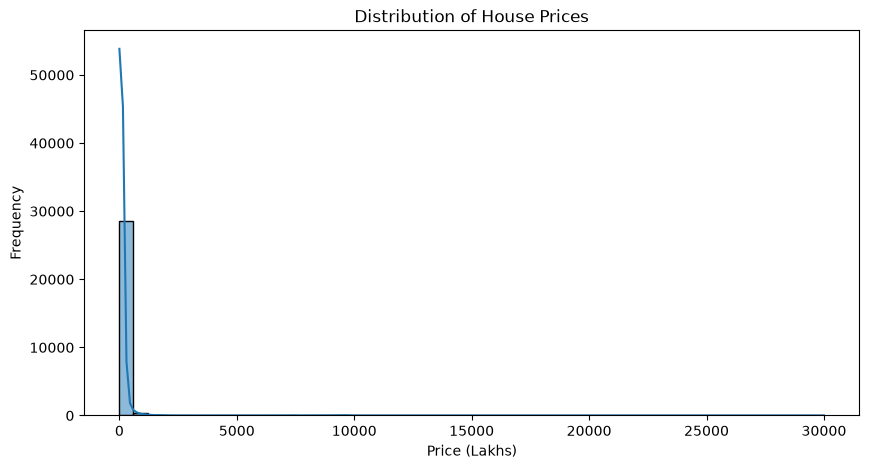

In [27]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['TARGET(PRICE_IN_LACS)'],
    bins=50,
    kde=True
)

plt.title('Distribution of House Prices')
plt.xlabel('Price (Lakhs)')
plt.ylabel('Frequency')
plt.show()

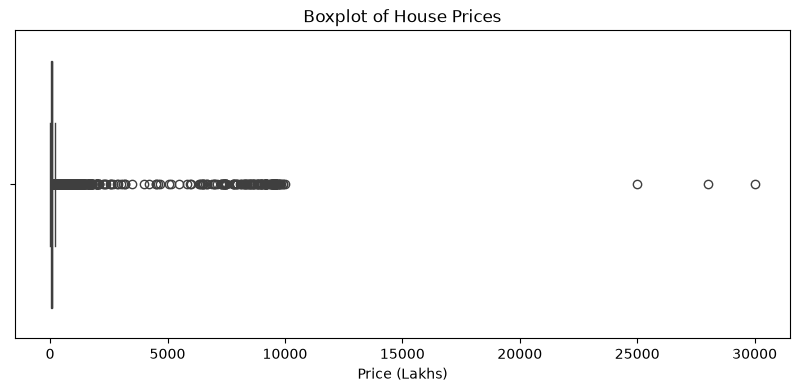

In [28]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df['TARGET(PRICE_IN_LACS)'])

plt.title('Boxplot of House Prices')
plt.xlabel('Price (Lakhs)')
plt.show()

In [29]:
# Top 20 most expensive properties
df.nlargest(
    20,
    'TARGET(PRICE_IN_LACS)'
)[[
    'POSTED_BY',
    'BHK_NO.',
    'SQUARE_FT',
    'ADDRESS',
    'CITY',
    'LONGITUDE',
    'LATITUDE',
    'TARGET(PRICE_IN_LACS)'
]]

,POSTED_BY,BHK_NO.,SQUARE_FT,ADDRESS,CITY,LONGITUDE,LATITUDE,TARGET(PRICE_IN_LACS)
11178,Dealer,3,1.875000e+08,"R.T. Nagar,Bangalore",Bangalore,13.018900,77.596300,30000.0
10694,Owner,3,2.545455e+08,"Malur,Bangalore",Bangalore,13.021000,77.938000,28000.0
15601,Owner,2,8.064516e+07,"Lakkasandra,Bangalore",Bangalore,12.795926,77.331535,25000.0
5952,Dealer,2,5.422570e+04,"Thane West,Lalitpur",Lalitpur,19.180000,72.963330,9990.0
10589,Dealer,3,8.322835e+04,"Chinchwad,Pune",Pune,18.627000,73.782900,9910.0
3749,Dealer,1,4.272398e+04,"Kanjur Marg (East),Maharashtra",Maharashtra,18.960000,72.820000,9900.0
9759,Dealer,2,4.968975e+04,"Laxmi Nagar,Mumbai",Mumbai,22.281215,70.789479,9850.0
14418,Dealer,1,4.377345e+04,"Hiranandani Estate,Lalitpur",Lalitpur,19.255098,72.981527,9800.0
15114,Dealer,3,1.652321e+05,"Sector-150 Noida,Noida",Noida,28.429614,77.481711,9790.0
4511,Dealer,3,1.394286e+05,"Sector-150 Noida,Noida",Noida,28.429614,77.481711,9760.0


In [30]:
Q1 = df['TARGET(PRICE_IN_LACS)'].quantile(0.25)
Q3 = df['TARGET(PRICE_IN_LACS)'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 38.0
Q3: 100.0
IQR: 62.0
Lower Bound: -55.0
Upper Bound: 193.0


In [31]:
price_outliers = df[
    (df['TARGET(PRICE_IN_LACS)'] < lower_bound) |
    (df['TARGET(PRICE_IN_LACS)'] > upper_bound)
]

print("Number of price outliers:", len(price_outliers))
print(
    "Percentage of price outliers:",
    round(len(price_outliers) / len(df) * 100, 2),
    "%"
)

Number of price outliers: 3045
Percentage of price outliers: 10.48 %


In [32]:
df['LOG_PRICE'] = np.log1p(df['TARGET(PRICE_IN_LACS)'])

print(
    "Original Price Skewness:",
    df['TARGET(PRICE_IN_LACS)'].skew()
)

print(
    "Log Price Skewness:",
    df['LOG_PRICE'].skew()
)

Original Price Skewness: 17.97197602615837
Log Price Skewness: 1.202083047800571


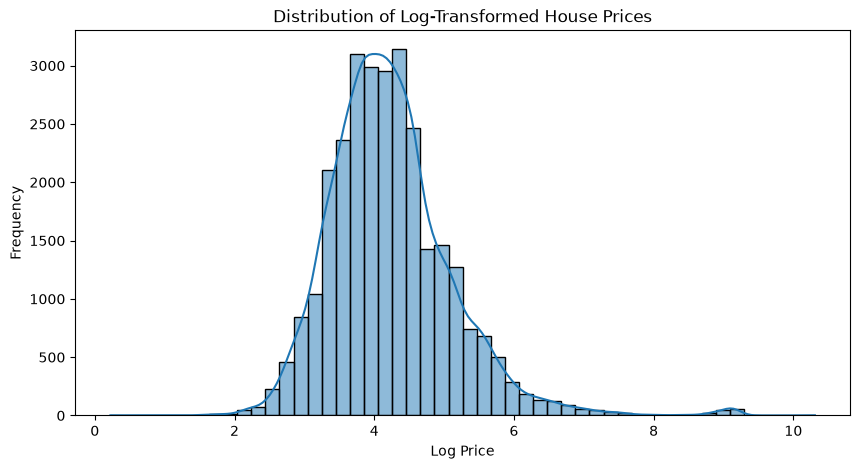

In [33]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['LOG_PRICE'],
    bins=50,
    kde=True
)

plt.title('Distribution of Log-Transformed House Prices')
plt.xlabel('Log Price')
plt.ylabel('Frequency')

plt.show()

In [34]:
df['SQUARE_FT'].describe()

count    2.905000e+04
mean     2.003171e+04
std      1.914411e+06
min      3.000000e+00
25%      9.000000e+02
50%      1.172742e+03
75%      1.550169e+03
max      2.545455e+08
Name: SQUARE_FT, dtype: float64

In [35]:
df['SQUARE_FT'].skew()

np.float64(115.81290137888708)

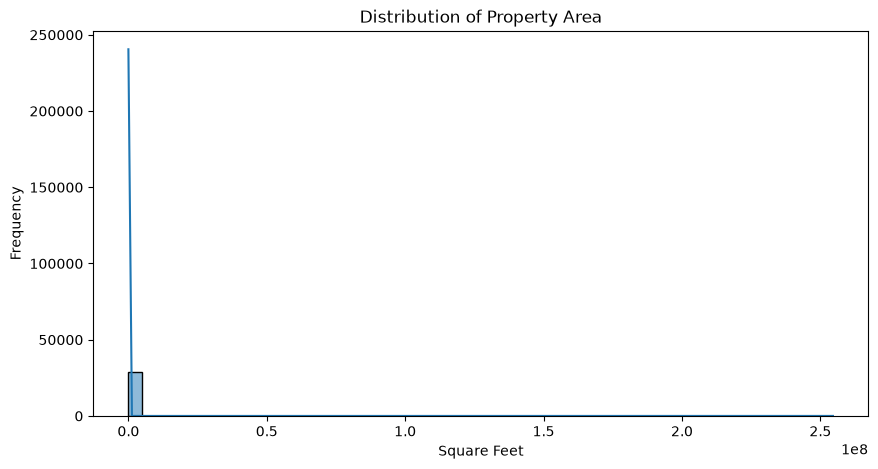

In [36]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['SQUARE_FT'],
    bins=50,
    kde=True
)

plt.title('Distribution of Property Area')
plt.xlabel('Square Feet')
plt.ylabel('Frequency')

plt.show()

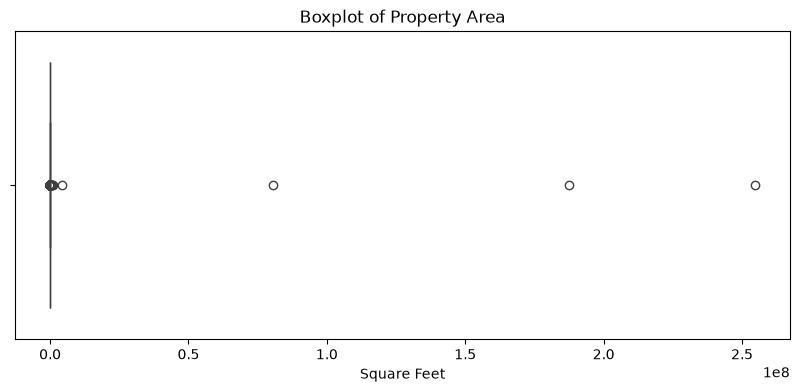

In [37]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df['SQUARE_FT'])

plt.title('Boxplot of Property Area')
plt.xlabel('Square Feet')

plt.show()

In [38]:
df.nlargest(
    20,
    'SQUARE_FT'
)[[
    'BHK_NO.',
    'SQUARE_FT',
    'ADDRESS',
    'CITY',
    'TARGET(PRICE_IN_LACS)'
]]

,BHK_NO.,SQUARE_FT,ADDRESS,CITY,TARGET(PRICE_IN_LACS)
10694,3,2.545455e+08,"Malur,Bangalore",Bangalore,28000.0
11178,3,1.875000e+08,"R.T. Nagar,Bangalore",Bangalore,30000.0
15601,2,8.064516e+07,"Lakkasandra,Bangalore",Bangalore,25000.0
24935,3,4.300000e+06,"New Kumaran Nagar,Chennai",Chennai,43.0
28212,2,8.750000e+05,"Ajit Singh Nagar,Vijayawada",Vijayawada,35.0
15475,3,7.928571e+05,"Sainik Colony,Jammu",Jammu,55.5
373,4,4.333333e+05,"Mulanthuruthy,Kochi",Kochi,65.0
21905,1,3.400000e+05,"Sayajipura,Vadodara",Vadodara,17.0
18859,4,2.460088e+05,"Gomti Nagar Extension,Lucknow",Lucknow,9523.0
12959,4,2.425000e+05,"Bariatu,Ranchi",Ranchi,9700.0


In [39]:
Q1_sqft = df['SQUARE_FT'].quantile(0.25)
Q3_sqft = df['SQUARE_FT'].quantile(0.75)

IQR_sqft = Q3_sqft - Q1_sqft

lower_sqft = Q1_sqft - 1.5 * IQR_sqft
upper_sqft = Q3_sqft + 1.5 * IQR_sqft

print("Q1:", Q1_sqft)
print("Q3:", Q3_sqft)
print("IQR:", IQR_sqft)
print("Lower Bound:", lower_sqft)
print("Upper Bound:", upper_sqft)

Q1: 900.0
Q3: 1550.169109
IQR: 650.1691089999999
Lower Bound: -75.2536634999999
Upper Bound: 2525.4227725


In [40]:
sqft_outliers = df[
    (df['SQUARE_FT'] < lower_sqft) |
    (df['SQUARE_FT'] > upper_sqft)
]

print("Number of SQUARE_FT outliers:", len(sqft_outliers))
print(
    "Percentage:",
    round(len(sqft_outliers) / len(df) * 100, 2),
    "%"
)

Number of SQUARE_FT outliers: 1612
Percentage: 5.55 %


In [42]:
df['PRICE_PER_SQFT'] = (
    df['TARGET(PRICE_IN_LACS)'] * 100000
) / df['SQUARE_FT']

df['PRICE_PER_SQFT'].describe()

count     29050.000000
mean       7518.995009
std       10902.834990
min           1.000000
25%        3550.000000
50%        5099.999999
75%        8065.000001
max      900000.000000
Name: PRICE_PER_SQFT, dtype: float64

In [43]:
df.nsmallest(
    20,
    'PRICE_PER_SQFT'
)[[
    'BHK_NO.',
    'SQUARE_FT',
    'CITY',
    'TARGET(PRICE_IN_LACS)',
    'PRICE_PER_SQFT'
]]

,BHK_NO.,SQUARE_FT,CITY,TARGET(PRICE_IN_LACS),PRICE_PER_SQFT
24935,3,4.300000e+06,Chennai,43.00,1.0
3876,10,4.250000e+04,Hosur,0.85,2.0
28212,2,8.750000e+05,Vijayawada,35.00,4.0
21905,1,3.400000e+05,Vadodara,17.00,5.0
15475,3,7.928571e+05,Jammu,55.50,7.0
10694,3,2.545455e+08,Bangalore,28000.00,11.0
13940,3,1.923077e+03,Bhubaneswar,0.25,13.0
373,4,4.333333e+05,Kochi,65.00,15.0
11178,3,1.875000e+08,Bangalore,30000.00,16.0
26845,3,1.526316e+03,Coimbatore,0.29,19.0


In [44]:
df.nlargest(
    20,
    'PRICE_PER_SQFT'
)[[
    'BHK_NO.',
    'SQUARE_FT',
    'CITY',
    'TARGET(PRICE_IN_LACS)',
    'PRICE_PER_SQFT'
]]

,BHK_NO.,SQUARE_FT,CITY,TARGET(PRICE_IN_LACS),PRICE_PER_SQFT
2091,2,5.000000,Chandigarh,45.0,900000.000000
13671,2,3.985594,Raipur,24.9,624749.999952
28038,3,900.001286,Jaipur,4200.0,466666.000008
3264,2,3.000000,Hajipur,12.0,400000.000000
24236,2,9.397110,Haldia,32.5,345851.000011
6434,2,900.000000,Kolkata,2700.0,300000.000000
15041,1,10.979906,Jalgaon,27.3,248635.999981
25285,1,600.000857,Jalgaon,1400.0,233333.000017
7596,1,700.001474,Surat,950.0,135713.999998
5417,2,650.000747,Anand,870.0,133846.000006


In [45]:
df['LOG_SQUARE_FT'] = np.log1p(df['SQUARE_FT'])

print("Original SQUARE_FT skewness:",
      df['SQUARE_FT'].skew())

print("Log SQUARE_FT skewness:",
      df['LOG_SQUARE_FT'].skew())

Original SQUARE_FT skewness: 115.81290137888708
Log SQUARE_FT skewness: 2.888118379278936


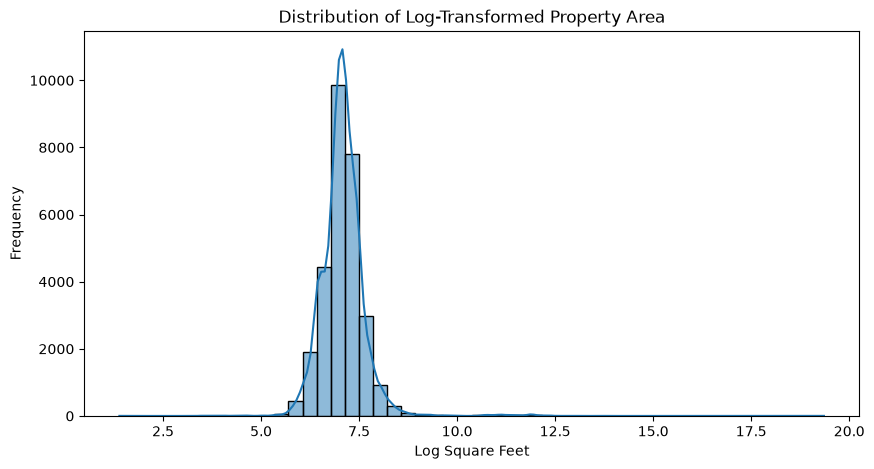

In [46]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df['LOG_SQUARE_FT'],
    bins=50,
    kde=True
)

plt.title('Distribution of Log-Transformed Property Area')
plt.xlabel('Log Square Feet')
plt.ylabel('Frequency')

plt.show()

In [47]:
df['SQUARE_FT'].quantile([
    0.90,
    0.95,
    0.97,
    0.98,
    0.99,
    0.995,
    0.999
])

0.900      2049.712858
0.950      2614.670719
0.970      3200.000000
0.980      3775.368115
0.990      5399.796811
0.995     21956.042904
0.999    154420.196035
Name: SQUARE_FT, dtype: float64

In [48]:
df['SQUARE_FT'].quantile([
    0.001,
    0.005,
    0.01,
    0.02,
    0.05
])

0.001    126.175144
0.005    328.086473
0.010    375.003104
0.020    436.638678
0.050    550.000000
Name: SQUARE_FT, dtype: float64

In [49]:
numerical_cols = [
    'BHK_NO.',
    'SQUARE_FT',
    'LONGITUDE',
    'LATITUDE',
    'TARGET(PRICE_IN_LACS)'
]

df[numerical_cols].skew().sort_values(ascending=False)

SQUARE_FT                115.812901
TARGET(PRICE_IN_LACS)     17.971976
BHK_NO.                    2.411951
LONGITUDE                  0.185040
LATITUDE                 -10.322082
dtype: float64

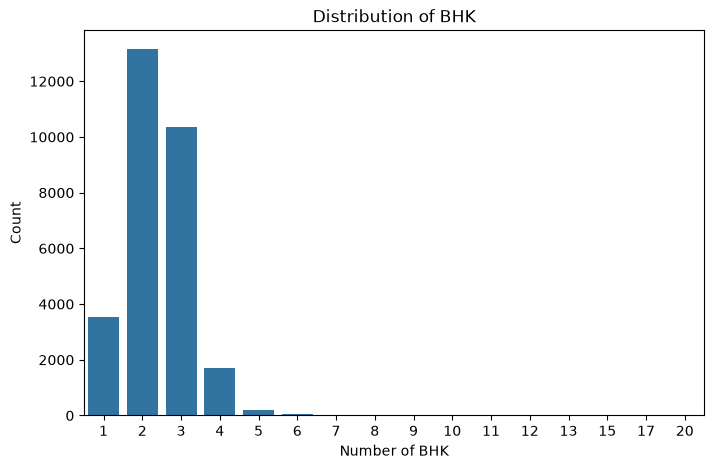

In [50]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x='BHK_NO.',
    data=df
)

plt.title('Distribution of BHK')
plt.xlabel('Number of BHK')
plt.ylabel('Count')

plt.show()

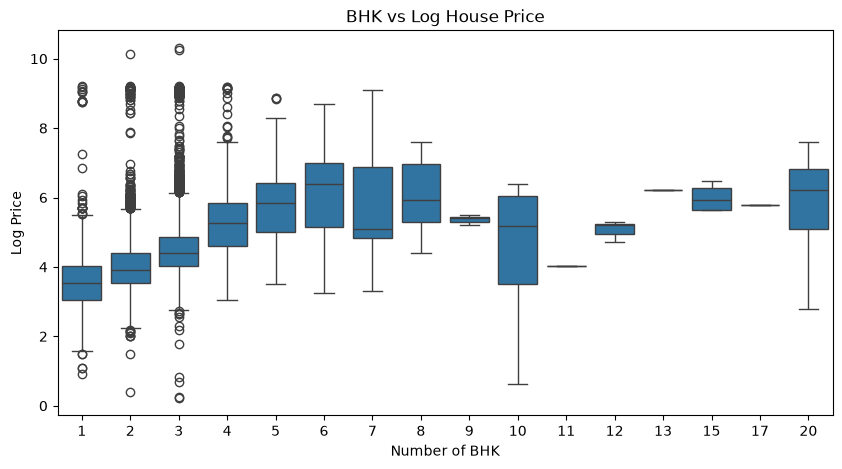

In [51]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x='BHK_NO.',
    y='LOG_PRICE',
    data=df
)

plt.title('BHK vs Log House Price')
plt.xlabel('Number of BHK')
plt.ylabel('Log Price')

plt.show()

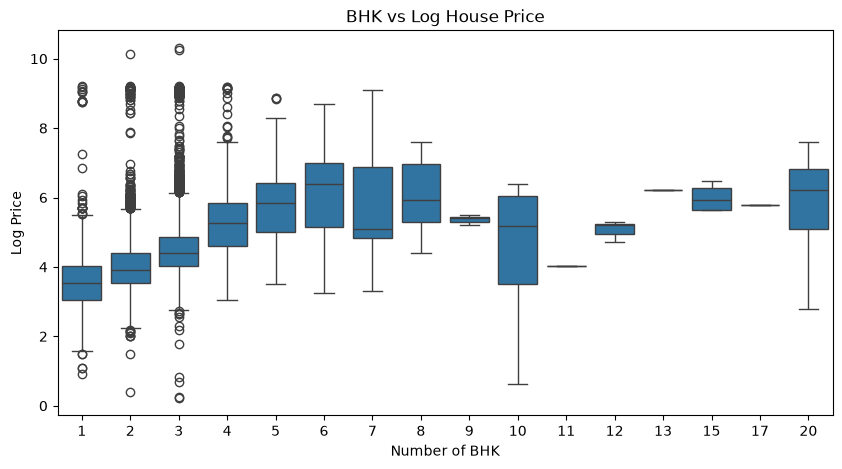

In [52]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x='BHK_NO.',
    y='LOG_PRICE',
    data=df
)

plt.title('BHK vs Log House Price')
plt.xlabel('Number of BHK')
plt.ylabel('Log Price')

plt.show()

In [53]:
# Check invalid latitude values
invalid_lat = df[
    (df['LATITUDE'] < -90) |
    (df['LATITUDE'] > 90)
]

print("Invalid latitude records:", len(invalid_lat))
print(
    "Percentage:",
    round(len(invalid_lat) / len(df) * 100, 2),
    "%"
)

invalid_lat[
    ['ADDRESS', 'CITY', 'LATITUDE', 'LONGITUDE']
].head(20)

Invalid latitude records: 215
Percentage: 0.74 %


,ADDRESS,CITY,LATITUDE,LONGITUDE
221,"Jalukbari,Guwahati",Guwahati,91.670312,26.154874
238,"GS Road,Guwahati",Guwahati,91.766670,26.166670
273,"Dharapur,Guwahati",Guwahati,91.627780,26.137220
404,"Satgaon,Guwahati",Guwahati,91.827348,26.157856
568,"7th Phase JP Nagar,Bangalore",Bangalore,136.000000,35.000000
625,"6th Phase JP Nagar,Bangalore",Bangalore,136.000000,35.000000
770,"AB Bypass Road,Indore",Indore,-117.001699,58.691753
818,"Padur,Chennai",Chennai,102.136839,19.894104
857,"Bhetapara,Guwahati",Guwahati,91.784650,26.115994
895,"Lokhra,Guwahati",Guwahati,91.748271,26.109987


In [54]:
invalid_long = df[
    (df['LONGITUDE'] < -180) |
    (df['LONGITUDE'] > 180)
]

print("Invalid longitude records:", len(invalid_long))

Invalid longitude records: 0


In [55]:
df.nsmallest(
    10, 'LATITUDE'
)[
    ['ADDRESS', 'CITY', 'LATITUDE', 'LONGITUDE']
]

,ADDRESS,CITY,LATITUDE,LONGITUDE
19259,"Near silver Estate,Latma road, Singhmore,Ranchi",Ranchi,-121.761248,37.294173
770,"AB Bypass Road,Indore",Indore,-117.001699,58.691753
8296,"AB Bypass Road,Indore",Indore,-117.001699,58.691753
11664,"AB Bypass Road,Indore",Indore,-117.001699,58.691753
17421,"AB Bypass Road,Indore",Indore,-117.001699,58.691753
18124,"AB Bypass Road,Indore",Indore,-117.001699,58.691753
25290,"AB Bypass Road,Indore",Indore,-117.001699,58.691753
2659,"Sector 132 Expressway,Noida",Noida,-114.053121,46.909674
10520,"Green Earth City ,Patan Road,Raipur,Raipur",Raipur,-105.279193,40.016847
2689,"Parel,Mumbai",Mumbai,-87.681841,42.049481


In [56]:
df.nlargest(
    10, 'LATITUDE'
)[
    ['ADDRESS', 'CITY', 'LATITUDE', 'LONGITUDE']
]

,ADDRESS,CITY,LATITUDE,LONGITUDE
27367,"100 Feet Road,Anand",Anand,152.962676,-27.550328
20410,"Brooke Bond First Cross,Bangalore",Bangalore,144.957843,-37.713008
20969,"Brooke Bond First Cross,Bangalore",Bangalore,144.957843,-37.713008
23526,"Brooke Bond First Cross,Bangalore",Bangalore,144.957843,-37.713008
15599,"3rd Phase JP Nagar,Bangalore",Bangalore,139.554449,35.578524
568,"7th Phase JP Nagar,Bangalore",Bangalore,136.000000,35.000000
625,"6th Phase JP Nagar,Bangalore",Bangalore,136.000000,35.000000
1752,"7th Phase JP Nagar,Bangalore",Bangalore,136.000000,35.000000
2868,"6th Phase JP Nagar,Bangalore",Bangalore,136.000000,35.000000
3214,"7th Phase JP Nagar,Bangalore",Bangalore,136.000000,35.000000


In [57]:
categorical_cols = [
    'POSTED_BY',
    'UNDER_CONSTRUCTION',
    'RERA',
    'BHK_OR_RK',
    'READY_TO_MOVE',
    'RESALE'
]

for col in categorical_cols:
    print("\n", col)
    print(df[col].value_counts())
    print(df[col].value_counts(normalize=True) * 100)


 POSTED_BY
POSTED_BY
Dealer     17961
Owner      10470
Builder      619
Name: count, dtype: int64
POSTED_BY
Dealer     61.827883
Owner      36.041308
Builder     2.130809
Name: proportion, dtype: float64

 UNDER_CONSTRUCTION
UNDER_CONSTRUCTION
0    23851
1     5199
Name: count, dtype: int64
UNDER_CONSTRUCTION
0    82.10327
1    17.89673
Name: proportion, dtype: float64

 RERA
RERA
0    19874
1     9176
Name: count, dtype: int64
RERA
0    68.413081
1    31.586919
Name: proportion, dtype: float64

 BHK_OR_RK
BHK_OR_RK
BHK    29026
RK        24
Name: count, dtype: int64
BHK_OR_RK
BHK    99.917384
RK      0.082616
Name: proportion, dtype: float64

 READY_TO_MOVE
READY_TO_MOVE
1    23851
0     5199
Name: count, dtype: int64
READY_TO_MOVE
1    82.10327
0    17.89673
Name: proportion, dtype: float64

 RESALE
RESALE
1    27027
0     2023
Name: count, dtype: int64
RESALE
1    93.036145
0     6.963855
Name: proportion, dtype: float64


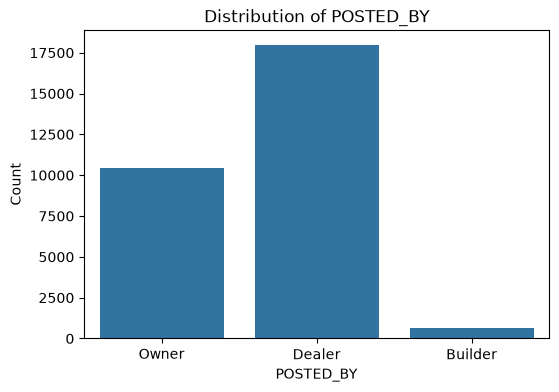

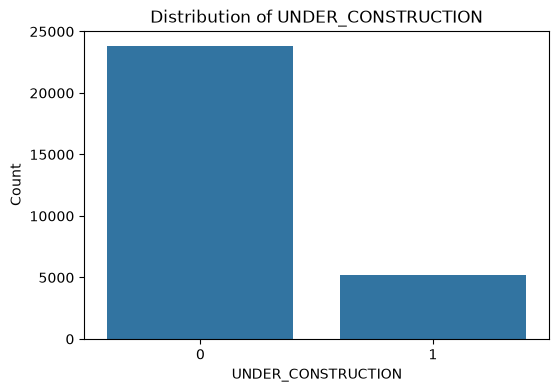

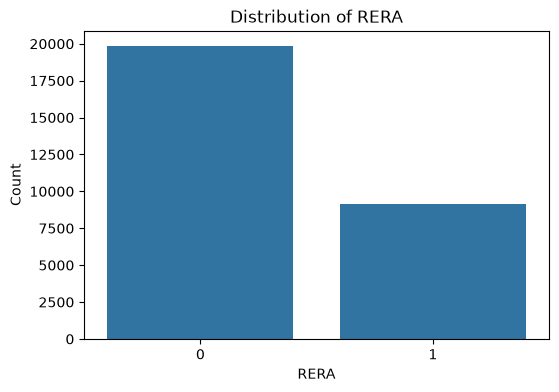

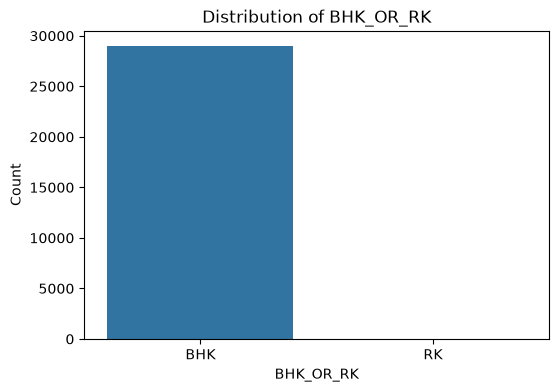

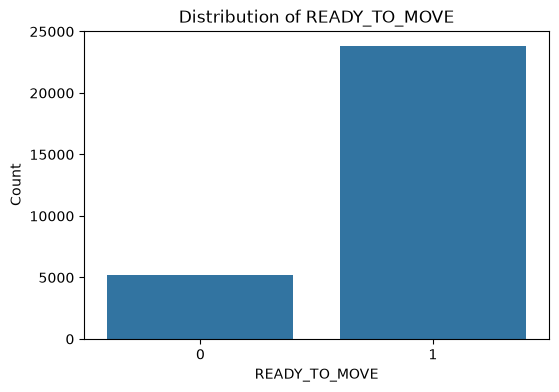

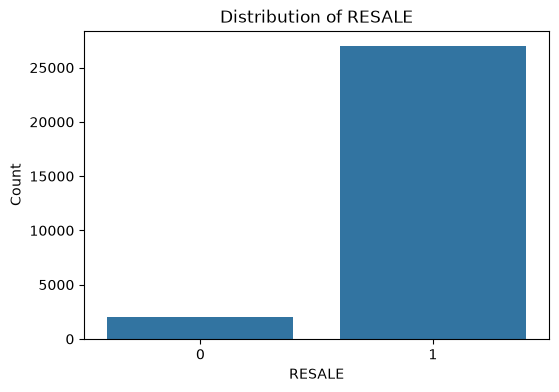

In [58]:
for col in categorical_cols:
    plt.figure(figsize=(6, 4))

    sns.countplot(
        x=col,
        data=df
    )

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Count')

    plt.show()

In [59]:
price_features = [
    'POSTED_BY',
    'UNDER_CONSTRUCTION',
    'RERA',
    'BHK_OR_RK',
    'RESALE'
]

for col in price_features:
    print(f"\n--- {col} ---")
    
    print(
        df.groupby(col)['TARGET(PRICE_IN_LACS)']
          .agg(['count', 'median', 'mean'])
          .round(2)
    )


--- POSTED_BY ---
           count  median    mean
POSTED_BY                       
Builder      619    42.0  246.72
Dealer     17961    80.0  185.29
Owner      10470    45.0   60.76

--- UNDER_CONSTRUCTION ---
                    count  median    mean
UNDER_CONSTRUCTION                       
0                   23851    60.0  125.14
1                    5199    65.6  217.76

--- RERA ---
      count  median    mean
RERA                       
0     19874    56.0  111.98
1      9176    74.0  206.11

--- BHK_OR_RK ---
           count  median    mean
BHK_OR_RK                       
BHK        29026   61.80  141.80
RK            24   42.45   41.04

--- RESALE ---
        count  median    mean
RESALE                       
0        2023    66.9  624.69
1       27027    61.0  105.56


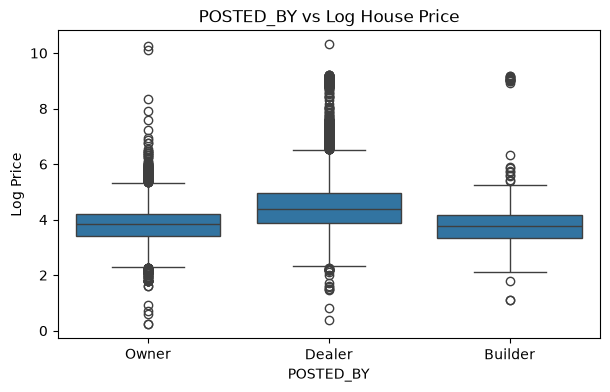

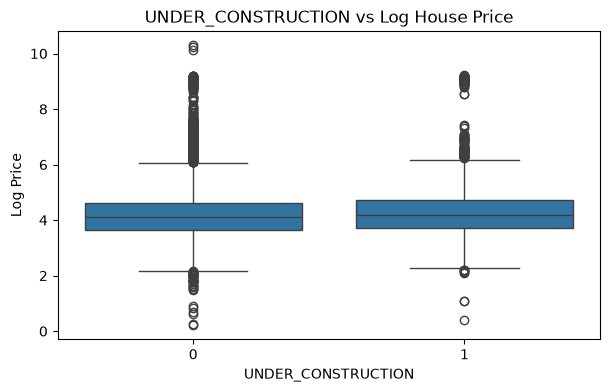

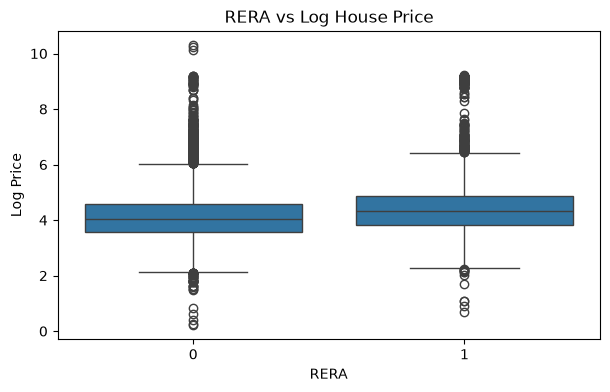

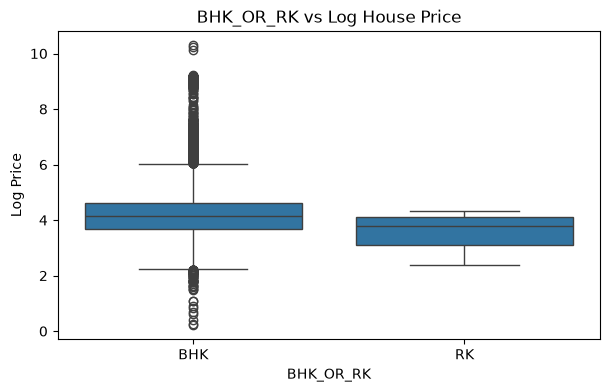

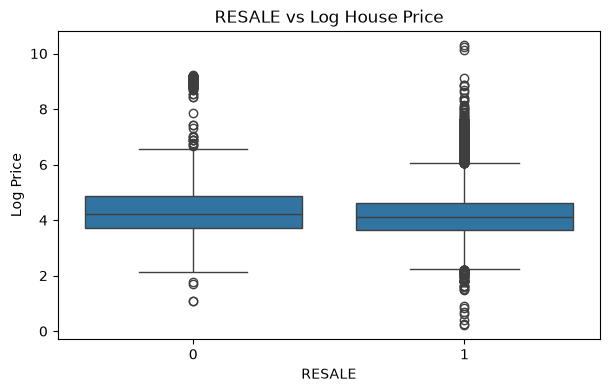

In [60]:
for col in price_features:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        x=col,
        y='LOG_PRICE',
        data=df
    )

    plt.title(f'{col} vs Log House Price')
    plt.xlabel(col)
    plt.ylabel('Log Price')

    plt.show()

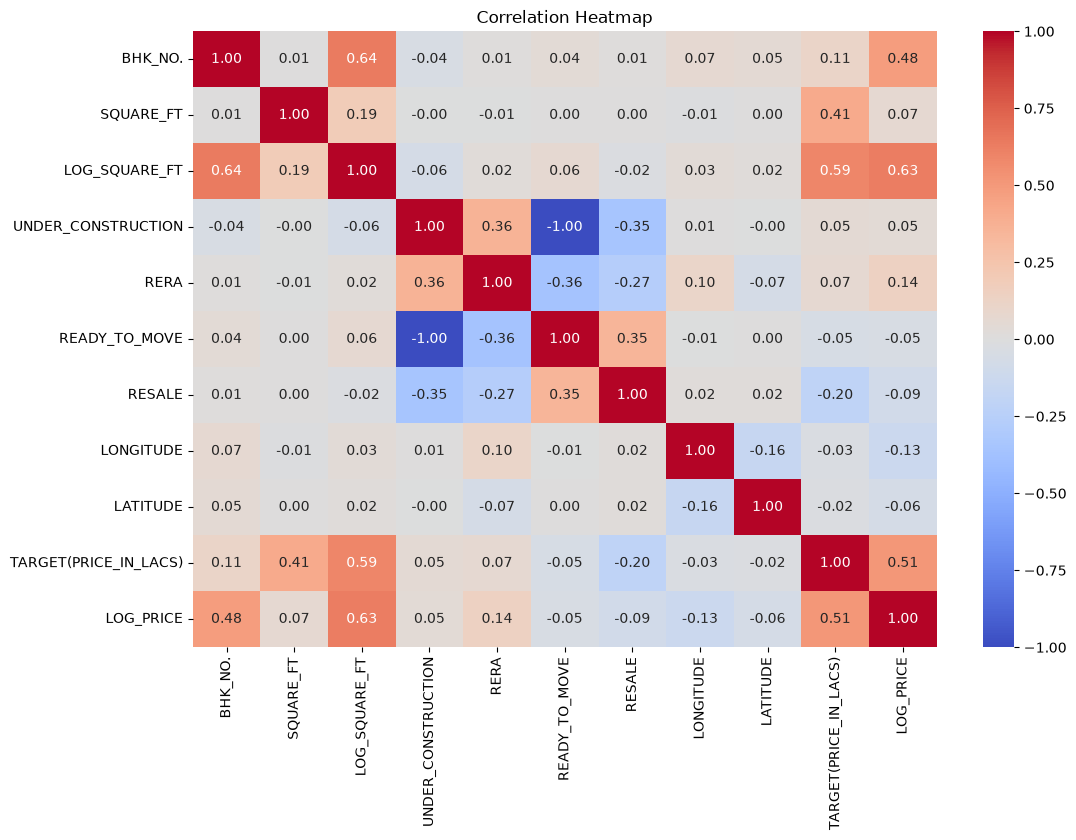

In [61]:
corr_cols = [
    'BHK_NO.',
    'SQUARE_FT',
    'LOG_SQUARE_FT',
    'UNDER_CONSTRUCTION',
    'RERA',
    'READY_TO_MOVE',
    'RESALE',
    'LONGITUDE',
    'LATITUDE',
    'TARGET(PRICE_IN_LACS)',
    'LOG_PRICE'
]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')
plt.show()

### Correlation and Feature Analysis

The correlation analysis showed that `LOG_SQUARE_FT` had the strongest
positive relationship with the log-transformed property price, with a
correlation of approximately 0.63. `BHK_NO.` also showed a moderate
positive correlation of approximately 0.48 with `LOG_PRICE`.

`RERA`, `UNDER_CONSTRUCTION`, and `RESALE` showed relatively weak linear
correlations with the target. However, these features were retained because
non-linear machine learning models may still capture useful relationships
between these variables and property prices.

`UNDER_CONSTRUCTION` and `READY_TO_MOVE` showed a perfect negative
correlation (-1.00), indicating that they contain redundant information.
Therefore, only `UNDER_CONSTRUCTION` will be retained.

The `BHK_OR_RK` feature was highly imbalanced, with only 24 RK properties
compared with 29,026 BHK properties. Therefore, it was excluded from the
model.

Due to the extreme positive skewness of `SQUARE_FT`, its log-transformed
version (`LOG_SQUARE_FT`) will be used for modelling.

We are intentionally excluding:
- READY_TO_MOVE → redundant with UNDER_CONSTRUCTION
- BHK_OR_RK → only 24 RK observations
- ADDRESS → very high cardinality
- SQUARE_FT → replaced by LOG_SQUARE_FT
- TARGET(PRICE_IN_LACS) → replaced by LOG_PRICE as the modelling target

In [62]:
model_df = df[[
    'POSTED_BY',
    'UNDER_CONSTRUCTION',
    'RERA',
    'BHK_NO.',
    'RESALE',
    'LOG_SQUARE_FT',
    'CITY',
    'LONGITUDE',
    'LATITUDE',
    'LOG_PRICE'
]].copy()

model_df.head()

,POSTED_BY,UNDER_CONSTRUCTION,RERA,BHK_NO.,RESALE,LOG_SQUARE_FT,CITY,LONGITUDE,LATITUDE,LOG_PRICE
0,Owner,0,0,2,1,7.171070,Bangalore,12.969910,77.597960,4.025352
1,Dealer,0,0,2,1,7.151485,Mysore,12.274538,76.644605,3.951244
2,Owner,0,0,2,1,6.839647,Bangalore,12.778033,77.632191,3.784190
3,Owner,0,1,2,1,6.836175,Ghaziabad,28.642300,77.344500,4.151040
4,Dealer,1,0,2,1,6.907765,Kolkata,22.592200,88.484911,4.119037


Based on the exploratory data analysis and correlation analysis, the final
features were selected for model development.

`READY_TO_MOVE` was excluded because it was perfectly negatively correlated
with `UNDER_CONSTRUCTION`. `BHK_OR_RK` was removed because the RK category
contained very few observations. `ADDRESS` was excluded due to its high
cardinality.

Since `SQUARE_FT` and the target price were highly positively skewed, their
log-transformed versions (`LOG_SQUARE_FT` and `LOG_PRICE`) were selected for
model development.

In [63]:
invalid_coordinates = model_df[
    (model_df['LATITUDE'] < 6) |
    (model_df['LATITUDE'] > 38) |
    (model_df['LONGITUDE'] < 68) |
    (model_df['LONGITUDE'] > 98)
]

print("Invalid coordinate records:", len(invalid_coordinates))

invalid_coordinates[
    ['CITY', 'LATITUDE', 'LONGITUDE']
].head(20)

Invalid coordinate records: 29050


,CITY,LATITUDE,LONGITUDE
0,Bangalore,77.597960,12.969910
1,Mysore,76.644605,12.274538
2,Bangalore,77.632191,12.778033
3,Ghaziabad,77.344500,28.642300
4,Kolkata,88.484911,22.592200
5,Kochi,76.282571,10.033280
6,Jaipur,75.795600,26.916347
7,Mohali,76.650000,30.740000
8,Bangalore,77.674002,13.054202
9,Chennai,80.140970,12.951610


In [64]:
df.rename(columns={
    'LONGITUDE': 'LATITUDE',
    'LATITUDE': 'LONGITUDE'
}, inplace=True)

In [65]:
model_df = df[[
    'POSTED_BY',
    'UNDER_CONSTRUCTION',
    'RERA',
    'BHK_NO.',
    'RESALE',
    'LOG_SQUARE_FT',
    'CITY',
    'LONGITUDE',
    'LATITUDE',
    'LOG_PRICE'
]].copy()

In [66]:
model_df[['CITY', 'LATITUDE', 'LONGITUDE']].head(10)

,CITY,LATITUDE,LONGITUDE
0,Bangalore,12.969910,77.597960
1,Mysore,12.274538,76.644605
2,Bangalore,12.778033,77.632191
3,Ghaziabad,28.642300,77.344500
4,Kolkata,22.592200,88.484911
5,Kochi,10.033280,76.282571
6,Jaipur,26.916347,75.795600
7,Mohali,30.740000,76.650000
8,Bangalore,13.054202,77.674002
9,Chennai,12.951610,80.140970


In [67]:
invalid_coordinates = model_df[
    (model_df['LATITUDE'] < 6) |
    (model_df['LATITUDE'] > 38) |
    (model_df['LONGITUDE'] < 68) |
    (model_df['LONGITUDE'] > 98)
]

print("Invalid coordinate records:", len(invalid_coordinates))

invalid_coordinates[
    ['CITY', 'LATITUDE', 'LONGITUDE']
].head(20)

Invalid coordinate records: 255


,CITY,LATITUDE,LONGITUDE
200,Kolkata,40.671972,-86.152929
327,Bangalore,50.817397,4.421450
568,Bangalore,35.000000,136.000000
625,Bangalore,35.000000,136.000000
770,Indore,58.691753,-117.001699
818,Chennai,19.894104,102.136839
1206,Bangalore,50.817397,4.421450
1589,Chennai,19.894104,102.136839
1686,Bangalore,35.373870,132.764401
1752,Bangalore,35.000000,136.000000


During EDA, it was observed that the values stored in the `LATITUDE` and
`LONGITUDE` columns appeared to be interchanged. For example, Bangalore
records contained values of approximately 77.6 under `LATITUDE` and 13.0
under `LONGITUDE`, whereas Bangalore's actual geographic coordinates are
approximately 13° N latitude and 77° E longitude.

Therefore, the latitude and longitude column names were corrected before
model development. The coordinates were subsequently validated using
reasonable geographic bounds for India.

In [68]:
# Keep only records with valid Indian coordinates
model_df = model_df[
    (model_df['LATITUDE'].between(6, 38)) &
    (model_df['LONGITUDE'].between(68, 98))
].copy()

# Reset index
model_df.reset_index(drop=True, inplace=True)

print("Dataset shape after removing invalid coordinates:", model_df.shape)

Dataset shape after removing invalid coordinates: (28795, 10)


### Treatment of Invalid Geographic Coordinates

During geographic data validation, 255 records were found to contain
invalid latitude and longitude values based on reasonable geographic
bounds for India.

These records represented less than 1% of the dataset and contained
clearly inconsistent geographic coordinates. Therefore, they were
removed rather than manually correcting or imputing the coordinates,
which could introduce inaccurate location information into the model

## Model Development

### Defining Independent and Target Variables

The dataset is divided into independent variables (`X`) and the target
variable (`y`). The log-transformed house price (`LOG_PRICE`) is used as
the target variable for model development.

In [70]:
# Independent variables
X = model_df.drop('LOG_PRICE', axis=1)

# Target variable
y = model_df['LOG_PRICE']

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (28795, 9)
Shape of y: (28795,)


In [71]:
X.head()

,POSTED_BY,UNDER_CONSTRUCTION,RERA,BHK_NO.,RESALE,LOG_SQUARE_FT,CITY,LONGITUDE,LATITUDE
0,Owner,0,0,2,1,7.171070,Bangalore,77.597960,12.969910
1,Dealer,0,0,2,1,7.151485,Mysore,76.644605,12.274538
2,Owner,0,0,2,1,6.839647,Bangalore,77.632191,12.778033
3,Owner,0,1,2,1,6.836175,Ghaziabad,77.344500,28.642300
4,Dealer,1,0,2,1,6.907765,Kolkata,88.484911,22.592200


In [72]:
y.head()

0    4.025352
1    3.951244
2    3.784190
3    4.151040
4    4.119037
Name: LOG_PRICE, dtype: float64

In [73]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (23036, 9)
X_test shape: (5759, 9)
y_train shape: (23036,)
y_test shape: (5759,)


In [74]:
categorical_cols = X_train.select_dtypes(include='object').columns

print("Categorical columns:")
print(categorical_cols)

Categorical columns:
Index(['POSTED_BY', 'CITY'], dtype='str')


In [75]:
print("POSTED_BY unique categories:",
      X_train['POSTED_BY'].nunique())

print("CITY unique categories:",
      X_train['CITY'].nunique())

POSTED_BY unique categories: 3
CITY unique categories: 241


In [76]:
city_counts = X_train['CITY'].value_counts()

print(city_counts.describe())

count     241.000000
mean       95.585062
std       344.651445
min         1.000000
25%         1.000000
50%         6.000000
75%        32.000000
max      3314.000000
Name: count, dtype: float64


In [77]:
city_counts.tail(20)

CITY
Jajpur       1
Silchar      1
Korba        1
Hassan       1
Siwan        1
Bhadrak      1
Bharatpur    1
Nagaur       1
Dahod        1
Godhra       1
Banswara     1
Salem        1
Washim       1
Raichur      1
Faizabad     1
Visnagar     1
Angul        1
Arrah        1
Bhiwani      1
Sagar        1
Name: count, dtype: int64

In [78]:
print("Cities appearing only once:",
      (city_counts == 1).sum())

print("Cities with fewer than 5 properties:",
      (city_counts < 5).sum())

print("Cities with fewer than 10 properties:",
      (city_counts < 10).sum())

print("Cities with fewer than 20 properties:",
      (city_counts < 20).sum())

Cities appearing only once: 61
Cities with fewer than 5 properties: 106
Cities with fewer than 10 properties: 133
Cities with fewer than 20 properties: 161


In [79]:
# Find cities having at least 10 properties in training data
city_counts = X_train['CITY'].value_counts()

common_cities = city_counts[city_counts >= 10].index

print("Number of common cities:", len(common_cities))

Number of common cities: 108


In [80]:
X_train = X_train.copy()
X_test = X_test.copy()

X_train['CITY'] = X_train['CITY'].where(
    X_train['CITY'].isin(common_cities),
    'Other'
)

X_test['CITY'] = X_test['CITY'].where(
    X_test['CITY'].isin(common_cities),
    'Other'
)

In [81]:
print("Unique cities in X_train:", X_train['CITY'].nunique())
print("Unique cities in X_test:", X_test['CITY'].nunique())

print("\nNumber of 'Other' records:")
print("Train:", (X_train['CITY'] == 'Other').sum())
print("Test:", (X_test['CITY'] == 'Other').sum())

Unique cities in X_train: 109
Unique cities in X_test: 109

Number of 'Other' records:
Train: 366
Test: 95


In [82]:
X_train['CITY'].value_counts().tail(10)

CITY
Mathura       14
Margao        13
Rudrapur      12
Jalgaon       12
Nainital      12
Kannur        11
Kakinada      10
Karad         10
Durg          10
Chandrapur    10
Name: count, dtype: int64

In [83]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_cols = ['POSTED_BY', 'CITY']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(
            handle_unknown='ignore',
            drop='first'
        ), categorical_cols)
    ],
    remainder='passthrough'
)

In [84]:
X_train_encoded = preprocessor.fit_transform(X_train)

X_test_encoded = preprocessor.transform(X_test)

print("X_train encoded shape:", X_train_encoded.shape)
print("X_test encoded shape:", X_test_encoded.shape)

X_train encoded shape: (23036, 117)
X_test encoded shape: (5759, 117)


In [85]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

categorical_cols = ['POSTED_BY', 'CITY']

scale_cols = [
    'LOG_SQUARE_FT',
    'LONGITUDE',
    'LATITUDE'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(
            handle_unknown='ignore',
            drop='first'
        ), categorical_cols),

        ('scale', StandardScaler(), scale_cols)
    ],
    remainder='passthrough'
)

In [86]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("X_train processed shape:", X_train_processed.shape)
print("X_test processed shape:", X_test_processed.shape)

X_train processed shape: (23036, 117)
X_test processed shape: (5759, 117)


In [87]:
#Linear Regression Model
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train_processed, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](117,)","[ 0.43, 0.36, 0.27,..., 0.01, 0.19,-0.15]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.959
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,117


In [88]:
y_train_pred_lr = lr_model.predict(X_train_processed)
y_test_pred_lr = lr_model.predict(X_test_processed)

In [89]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Training metrics
train_r2 = r2_score(y_train, y_train_pred_lr)
train_mae = mean_absolute_error(y_train, y_train_pred_lr)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_lr))

# Testing metrics
test_r2 = r2_score(y_test, y_test_pred_lr)
test_mae = mean_absolute_error(y_test, y_test_pred_lr)
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_lr))

print("Linear Regression Results")
print("-------------------------")

print("Train R2:", round(train_r2, 4))
print("Test R2:", round(test_r2, 4))

print("Train MAE:", round(train_mae, 4))
print("Test MAE:", round(test_mae, 4))

print("Train RMSE:", round(train_rmse, 4))
print("Test RMSE:", round(test_rmse, 4))

Linear Regression Results
-------------------------
Train R2: 0.7557
Test R2: 0.7619
Train MAE: 0.3056
Test MAE: 0.3053
Train RMSE: 0.4382
Test RMSE: 0.4269


In [90]:
#decision tree regressor
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

In [91]:
y_train_pred_dt = dt_model.predict(X_train_processed)
y_test_pred_dt = dt_model.predict(X_test_processed)

In [92]:
# Training metrics
dt_train_r2 = r2_score(y_train, y_train_pred_dt)
dt_train_mae = mean_absolute_error(y_train, y_train_pred_dt)
dt_train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred_dt)
)

# Testing metrics
dt_test_r2 = r2_score(y_test, y_test_pred_dt)
dt_test_mae = mean_absolute_error(y_test, y_test_pred_dt)
dt_test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred_dt)
)

print("Decision Tree Regression Results")
print("--------------------------------")

print("Train R2:", round(dt_train_r2, 4))
print("Test R2:", round(dt_test_r2, 4))

print("Train MAE:", round(dt_train_mae, 4))
print("Test MAE:", round(dt_test_mae, 4))

print("Train RMSE:", round(dt_train_rmse, 4))
print("Test RMSE:", round(dt_test_rmse, 4))

Decision Tree Regression Results
--------------------------------
Train R2: 0.9985
Test R2: 0.7494
Train MAE: 0.002
Test MAE: 0.2804
Train RMSE: 0.0339
Test RMSE: 0.438


In [93]:
#tune decision tree
from sklearn.tree import DecisionTreeRegressor

dt_tuned = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

dt_tuned.fit(X_train_processed, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with 

In [94]:
y_train_pred_dt_tuned = dt_tuned.predict(X_train_processed)
y_test_pred_dt_tuned = dt_tuned.predict(X_test_processed)

In [95]:
dt_tuned_train_r2 = r2_score(y_train, y_train_pred_dt_tuned)
dt_tuned_test_r2 = r2_score(y_test, y_test_pred_dt_tuned)

dt_tuned_train_mae = mean_absolute_error(
    y_train, y_train_pred_dt_tuned
)
dt_tuned_test_mae = mean_absolute_error(
    y_test, y_test_pred_dt_tuned
)

dt_tuned_train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred_dt_tuned)
)
dt_tuned_test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred_dt_tuned)
)

print("Tuned Decision Tree Results")
print("---------------------------")

print("Train R2:", round(dt_tuned_train_r2, 4))
print("Test R2:", round(dt_tuned_test_r2, 4))

print("Train MAE:", round(dt_tuned_train_mae, 4))
print("Test MAE:", round(dt_tuned_test_mae, 4))

print("Train RMSE:", round(dt_tuned_train_rmse, 4))
print("Test RMSE:", round(dt_tuned_test_rmse, 4))

Tuned Decision Tree Results
---------------------------
Train R2: 0.8451
Test R2: 0.7975
Train MAE: 0.2484
Test MAE: 0.2776
Train RMSE: 0.349
Test RMSE: 0.3937


In [96]:
#random forest regressor
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

In [97]:
y_train_pred_rf = rf_model.predict(X_train_processed)
y_test_pred_rf = rf_model.predict(X_test_processed)

In [98]:
# Training metrics
rf_train_r2 = r2_score(y_train, y_train_pred_rf)
rf_train_mae = mean_absolute_error(y_train, y_train_pred_rf)
rf_train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred_rf)
)

# Testing metrics
rf_test_r2 = r2_score(y_test, y_test_pred_rf)
rf_test_mae = mean_absolute_error(y_test, y_test_pred_rf)
rf_test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred_rf)
)

print("Random Forest Regression Results")
print("--------------------------------")

print("Train R2:", round(rf_train_r2, 4))
print("Test R2:", round(rf_test_r2, 4))

print("Train MAE:", round(rf_train_mae, 4))
print("Test MAE:", round(rf_test_mae, 4))

print("Train RMSE:", round(rf_train_rmse, 4))
print("Test RMSE:", round(rf_test_rmse, 4))

Random Forest Regression Results
--------------------------------
Train R2: 0.9789
Test R2: 0.8516
Train MAE: 0.083
Test MAE: 0.2201
Train RMSE: 0.1289
Test RMSE: 0.337


In [99]:
#Tune Random Forest
rf_tuned = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

rf_tuned.fit(X_train_processed, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",4
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,

In [100]:
y_train_pred_rf_tuned = rf_tuned.predict(X_train_processed)
y_test_pred_rf_tuned = rf_tuned.predict(X_test_processed)

In [101]:
# Training metrics
rf_tuned_train_r2 = r2_score(y_train, y_train_pred_rf_tuned)
rf_tuned_train_mae = mean_absolute_error(y_train, y_train_pred_rf_tuned)
rf_tuned_train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred_rf_tuned)
)

# Testing metrics
rf_tuned_test_r2 = r2_score(y_test, y_test_pred_rf_tuned)
rf_tuned_test_mae = mean_absolute_error(y_test, y_test_pred_rf_tuned)
rf_tuned_test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred_rf_tuned)
)

print("Tuned Random Forest Results")
print("---------------------------")

print("Train R2:", round(rf_tuned_train_r2, 4))
print("Test R2:", round(rf_tuned_test_r2, 4))

print("Train MAE:", round(rf_tuned_train_mae, 4))
print("Test MAE:", round(rf_tuned_test_mae, 4))

print("Train RMSE:", round(rf_tuned_train_rmse, 4))
print("Test RMSE:", round(rf_tuned_test_rmse, 4))

Tuned Random Forest Results
---------------------------
Train R2: 0.7621
Test R2: 0.7476
Train MAE: 0.3062
Test MAE: 0.3171
Train RMSE: 0.4325
Test RMSE: 0.4395


In [102]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

rf_base = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, 20, 25, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 0.5, 0.8]
}

rf_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_grid,
    n_iter=20,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train_processed, y_train)

print("Best Parameters:")
print(rf_search.best_params_)

print("\nBest CV R2:")
print(round(rf_search.best_score_, 4))

Best Parameters:
{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': None}

Best CV R2:
0.852


In [103]:
# Get the best Random Forest model
rf_best = rf_search.best_estimator_

# Predictions
y_train_pred_rf_best = rf_best.predict(X_train_processed)
y_test_pred_rf_best = rf_best.predict(X_test_processed)

# R2
rf_best_train_r2 = r2_score(y_train, y_train_pred_rf_best)
rf_best_test_r2 = r2_score(y_test, y_test_pred_rf_best)

# MAE
rf_best_train_mae = mean_absolute_error(
    y_train, y_train_pred_rf_best
)

rf_best_test_mae = mean_absolute_error(
    y_test, y_test_pred_rf_best
)

# RMSE
rf_best_train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred_rf_best)
)

rf_best_test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred_rf_best)
)

print("Optimized Random Forest Results")
print("--------------------------------")

print("Train R2:", round(rf_best_train_r2, 4))
print("Test R2:", round(rf_best_test_r2, 4))

print("Train MAE:", round(rf_best_train_mae, 4))
print("Test MAE:", round(rf_best_test_mae, 4))

print("Train RMSE:", round(rf_best_train_rmse, 4))
print("Test RMSE:", round(rf_best_test_rmse, 4))

Optimized Random Forest Results
--------------------------------
Train R2: 0.9796
Test R2: 0.86
Train MAE: 0.0811
Test MAE: 0.2161
Train RMSE: 0.1266
Test RMSE: 0.3274


In [104]:
#gradient boosting regressor
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(
    random_state=42
)

gbr.fit(X_train_processed, y_train)

# Predictions
y_train_pred_gbr = gbr.predict(X_train_processed)
y_test_pred_gbr = gbr.predict(X_test_processed)

In [105]:
# R2
gbr_train_r2 = r2_score(y_train, y_train_pred_gbr)
gbr_test_r2 = r2_score(y_test, y_test_pred_gbr)

# MAE
gbr_train_mae = mean_absolute_error(
    y_train, y_train_pred_gbr
)

gbr_test_mae = mean_absolute_error(
    y_test, y_test_pred_gbr
)

# RMSE
gbr_train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred_gbr)
)

gbr_test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred_gbr)
)

print("Gradient Boosting Regression Results")
print("------------------------------------")

print("Train R2:", round(gbr_train_r2, 4))
print("Test R2:", round(gbr_test_r2, 4))

print("Train MAE:", round(gbr_train_mae, 4))
print("Test MAE:", round(gbr_test_mae, 4))

print("Train RMSE:", round(gbr_train_rmse, 4))
print("Test RMSE:", round(gbr_test_rmse, 4))

Gradient Boosting Regression Results
------------------------------------
Train R2: 0.822
Test R2: 0.8038
Train MAE: 0.2723
Test MAE: 0.2789
Train RMSE: 0.3741
Test RMSE: 0.3875


The model achieved a training R² of 0.8220 and testing R² of 0.8038. The relatively small difference between training and testing performance indicates good generalization with no significant overfitting. However, its test performance was lower than the optimized Random Forest model.

In [109]:
%pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.


In [110]:
import xgboost

print(xgboost.__version__)

3.4.1


In [111]:
#xgboost regressor
from xgboost import XGBRegressor

xgb = XGBRegressor(
    random_state=42,
    objective='reg:squarederror'
)

xgb.fit(X_train_processed, y_train)

# Predictions
y_train_pred_xgb = xgb.predict(X_train_processed)
y_test_pred_xgb = xgb.predict(X_test_processed)

In [112]:
# R2
xgb_train_r2 = r2_score(y_train, y_train_pred_xgb)
xgb_test_r2 = r2_score(y_test, y_test_pred_xgb)

# MAE
xgb_train_mae = mean_absolute_error(
    y_train, y_train_pred_xgb
)

xgb_test_mae = mean_absolute_error(
    y_test, y_test_pred_xgb
)

# RMSE
xgb_train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred_xgb)
)

xgb_test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred_xgb)
)

print("XGBoost Regression Results")
print("--------------------------")

print("Train R2:", round(xgb_train_r2, 4))
print("Test R2:", round(xgb_test_r2, 4))

print("Train MAE:", round(xgb_train_mae, 4))
print("Test MAE:", round(xgb_test_mae, 4))

print("Train RMSE:", round(xgb_train_rmse, 4))
print("Test RMSE:", round(xgb_test_rmse, 4))

XGBoost Regression Results
--------------------------
Train R2: 0.9039
Test R2: 0.8671
Train MAE: 0.1955
Test MAE: 0.2245
Train RMSE: 0.2748
Test RMSE: 0.319


In [113]:
#tune xgboost
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor

xgb_base = XGBRegressor(
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

xgb_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=xgb_params,
    n_iter=15,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

xgb_search.fit(X_train_processed, y_train)

print("Best Parameters:")
print(xgb_search.best_params_)

print("\nBest CV R2:")
print(round(xgb_search.best_score_, 4))

Best Parameters:
{'subsample': 1.0, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.8}

Best CV R2:
0.8477


In [114]:
# Get best XGBoost model
xgb_best = xgb_search.best_estimator_

# Predictions
y_train_pred_xgb_best = xgb_best.predict(X_train_processed)
y_test_pred_xgb_best = xgb_best.predict(X_test_processed)

# R2
xgb_best_train_r2 = r2_score(y_train, y_train_pred_xgb_best)
xgb_best_test_r2 = r2_score(y_test, y_test_pred_xgb_best)

# MAE
xgb_best_train_mae = mean_absolute_error(
    y_train, y_train_pred_xgb_best
)

xgb_best_test_mae = mean_absolute_error(
    y_test, y_test_pred_xgb_best
)

# RMSE
xgb_best_train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred_xgb_best)
)

xgb_best_test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred_xgb_best)
)

print("Optimized XGBoost Results")
print("-------------------------")

print("Train R2:", round(xgb_best_train_r2, 4))
print("Test R2:", round(xgb_best_test_r2, 4))

print("Train MAE:", round(xgb_best_train_mae, 4))
print("Test MAE:", round(xgb_best_test_mae, 4))

print("Train RMSE:", round(xgb_best_train_rmse, 4))
print("Test RMSE:", round(xgb_best_test_rmse, 4))

Optimized XGBoost Results
-------------------------
Train R2: 0.8727
Test R2: 0.8556
Train MAE: 0.2271
Test MAE: 0.2404
Train RMSE: 0.3163
Test RMSE: 0.3324


In [115]:
#KNN Regressor
from sklearn.neighbors import KNeighborsRegressor

knn = KNeighborsRegressor(
    n_neighbors=5
)

knn.fit(X_train_processed, y_train)

# Predictions
y_train_pred_knn = knn.predict(X_train_processed)
y_test_pred_knn = knn.predict(X_test_processed)

In [116]:
# R2
knn_train_r2 = r2_score(y_train, y_train_pred_knn)
knn_test_r2 = r2_score(y_test, y_test_pred_knn)

# MAE
knn_train_mae = mean_absolute_error(
    y_train, y_train_pred_knn
)

knn_test_mae = mean_absolute_error(
    y_test, y_test_pred_knn
)

# RMSE
knn_train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred_knn)
)

knn_test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred_knn)
)

print("KNN Regression Results")
print("----------------------")

print("Train R2:", round(knn_train_r2, 4))
print("Test R2:", round(knn_test_r2, 4))

print("Train MAE:", round(knn_train_mae, 4))
print("Test MAE:", round(knn_test_mae, 4))

print("Train RMSE:", round(knn_train_rmse, 4))
print("Test RMSE:", round(knn_test_rmse, 4))

KNN Regression Results
----------------------
Train R2: 0.8703
Test R2: 0.7971
Train MAE: 0.2215
Test MAE: 0.2753
Train RMSE: 0.3194
Test RMSE: 0.3941


In [117]:
#SVR
from sklearn.svm import SVR

# Create SVR model
svr = SVR()

# Train model
svr.fit(X_train_processed, y_train)

# Predictions
y_train_pred_svr = svr.predict(X_train_processed)
y_test_pred_svr = svr.predict(X_test_processed)

In [118]:
# R2
svr_train_r2 = r2_score(y_train, y_train_pred_svr)
svr_test_r2 = r2_score(y_test, y_test_pred_svr)

# MAE
svr_train_mae = mean_absolute_error(
    y_train, y_train_pred_svr
)

svr_test_mae = mean_absolute_error(
    y_test, y_test_pred_svr
)

# RMSE
svr_train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred_svr)
)

svr_test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred_svr)
)

print("SVR Results")
print("----------------------")

print("Train R2:", round(svr_train_r2, 4))
print("Test R2:", round(svr_test_r2, 4))

print("Train MAE:", round(svr_train_mae, 4))
print("Test MAE:", round(svr_test_mae, 4))

print("Train RMSE:", round(svr_train_rmse, 4))
print("Test RMSE:", round(svr_test_rmse, 4))

SVR Results
----------------------
Train R2: 0.8293
Test R2: 0.8215
Train MAE: 0.2572
Test MAE: 0.265
Train RMSE: 0.3664
Test RMSE: 0.3696


In [119]:
import pandas as pd

model_comparison = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Tuned Decision Tree',
        'Random Forest',
        'Optimized Random Forest',
        'Gradient Boosting',
        'XGBoost',
        'Optimized XGBoost',
        'KNN',
        'SVR'
    ],
    
    'Train R2': [
        train_r2,
        dt_tuned_train_r2,
        rf_train_r2,
        rf_best_train_r2,
        gbr_train_r2,
        xgb_train_r2,
        xgb_best_train_r2,
        knn_train_r2,
        svr_train_r2
    ],
    
    'Test R2': [
        test_r2,
        dt_tuned_test_r2,
        rf_test_r2,
        rf_best_test_r2,
        gbr_test_r2,
        xgb_test_r2,
        xgb_best_test_r2,
        knn_test_r2,
        svr_test_r2
    ],
    
    'Test MAE': [
        test_mae,
        dt_tuned_test_mae,
        rf_test_mae,
        rf_best_test_mae,
        gbr_test_mae,
        xgb_test_mae,
        xgb_best_test_mae,
        knn_test_mae,
        svr_test_mae
    ],
    
    'Test RMSE': [
        test_rmse,
        dt_tuned_test_rmse,
        rf_test_rmse,
        rf_best_test_rmse,
        gbr_test_rmse,
        xgb_test_rmse,
        xgb_best_test_rmse,
        knn_test_rmse,
        svr_test_rmse
    ]
})

model_comparison.round(4)

,Model,Train R2,Test R2,Test MAE,Test RMSE
0,Linear Regression,0.7557,0.7619,0.3053,0.4269
1,Tuned Decision Tree,0.8451,0.7975,0.2776,0.3937
2,Random Forest,0.9789,0.8516,0.2201,0.3370
3,Optimized Random Forest,0.9796,0.8600,0.2161,0.3274
4,Gradient Boosting,0.8220,0.8038,0.2789,0.3875
5,XGBoost,0.9039,0.8671,0.2245,0.3190
6,Optimized XGBoost,0.8727,0.8556,0.2404,0.3324
7,KNN,0.8703,0.7971,0.2753,0.3941
8,SVR,0.8293,0.8215,0.2650,0.3696


## Final Model Selection

Based on the comparison of all regression models, XGBoost was selected as the final model.

The XGBoost model achieved a Test R² of 0.8671, indicating that approximately 86.7% of the variation in the log-transformed property prices is explained by the model.

It also achieved a Test MAE of 0.2245 and the lowest Test RMSE of 0.3190 among the evaluated models.

Although the Optimized Random Forest achieved a slightly lower MAE of 0.2161, XGBoost provided the best overall performance in terms of Test R² and RMSE.

Hyperparameter tuning of XGBoost did not improve its test performance. Therefore, the original XGBoost model was retained as the final model.

convert predictions back to actual price

In [124]:
# Convert log prices back to original price scale

y_test_actual = np.expm1(y_test)
y_pred_actual = np.expm1(y_test_pred_xgb)

price_comparison = pd.DataFrame({
    'Actual Price (Lacs)': y_test_actual,
    'Predicted Price (Lacs)': y_pred_actual
})

price_comparison.head(10)

,Actual Price (Lacs),Predicted Price (Lacs)
2579,100.0,103.913956
5505,40.5,41.757381
27723,180.0,167.679382
16795,40.0,33.633205
23366,17.0,17.114302
17242,65.0,40.214664
11959,49.2,43.393940
24991,120.0,70.887619
20482,38.1,49.014763
26881,63.0,78.168701


In [125]:
mae_actual = mean_absolute_error(
    y_test_actual,
    y_pred_actual
)

rmse_actual = np.sqrt(
    mean_squared_error(
        y_test_actual,
        y_pred_actual
    )
)

print("MAE on Original Price Scale:",
      round(mae_actual, 2), "Lakhs")

print("RMSE on Original Price Scale:",
      round(rmse_actual, 2), "Lakhs")

MAE on Original Price Scale: 32.24 Lakhs
RMSE on Original Price Scale: 164.76 Lakhs


In [126]:
mae_actual = mean_absolute_error(
    y_test_actual,
    y_pred_actual
)

rmse_actual = np.sqrt(
    mean_squared_error(
        y_test_actual,
        y_pred_actual
    )
)

print("MAE on Original Price Scale:",
      round(mae_actual, 2), "Lakhs")

print("RMSE on Original Price Scale:",
      round(rmse_actual, 2), "Lakhs")

MAE on Original Price Scale: 32.24 Lakhs
RMSE on Original Price Scale: 164.76 Lakhs


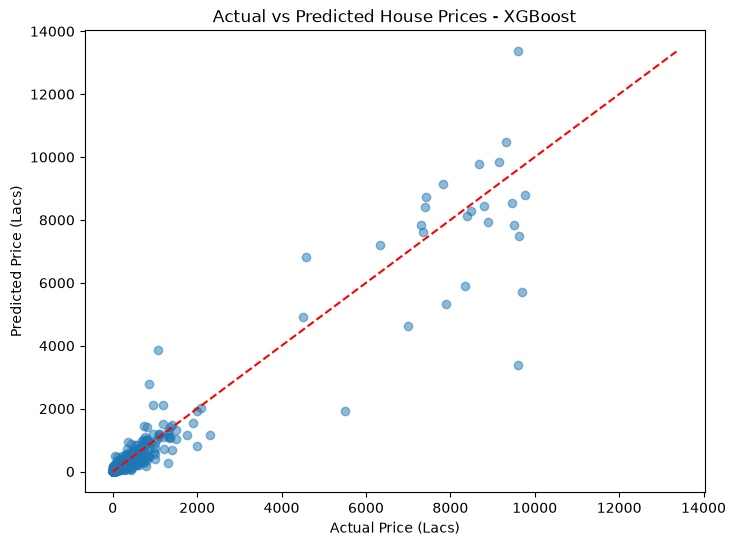

In [127]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_actual,
    y_pred_actual,
    alpha=0.5
)

min_val = min(y_test_actual.min(), y_pred_actual.min())
max_val = max(y_test_actual.max(), y_pred_actual.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--'
)

plt.xlabel("Actual Price (Lacs)")
plt.ylabel("Predicted Price (Lacs)")
plt.title("Actual vs Predicted House Prices - XGBoost")

plt.show()

In [128]:
price_comparison['Absolute Error'] = abs(
    price_comparison['Actual Price (Lacs)'] -
    price_comparison['Predicted Price (Lacs)']
)

price_comparison.sort_values(
    by='Absolute Error',
    ascending=False
).head(20)

,Actual Price (Lacs),Predicted Price (Lacs),Absolute Error
3858,9600.0,3402.594727,6197.405273
12848,9700.0,5714.156738,3985.843262
12904,9600.0,13357.758789,3757.758789
24291,5500.0,1925.106323,3574.893677
1282,1070.0,3849.236572,2779.236572
12273,7900.0,5342.083008,2557.916992
27396,8340.0,5888.314453,2451.685547
16897,7000.0,4640.836426,2359.163574
8960,4590.0,6834.614746,2244.614746
13197,9630.0,7490.933594,2139.066406


In [129]:
from sklearn.metrics import mean_absolute_percentage_error

mape = mean_absolute_percentage_error(
    y_test_actual,
    y_pred_actual
) * 100

print("MAPE:", round(mape, 2), "%")

MAPE: 26.81 %


The selected XGBoost model achieved a Test R² of 0.8671 on the
log-transformed target, indicating strong predictive performance.

After transforming the predictions back to the original price scale,
the model achieved an MAE of 32.24 lakhs and an RMSE of 164.76 lakhs.
The model also achieved a MAPE of 26.81%.

The Actual vs Predicted plot indicates that predictions are generally
closer to the actual values for the majority of properties, while
larger prediction errors are observed for some extremely high-priced
properties.

The substantially higher RMSE compared with MAE is mainly due to these
large prediction errors, since RMSE gives greater weight to extreme
errors.

Overall, XGBoost demonstrated the best predictive performance among
the evaluated models and was selected as the final model.

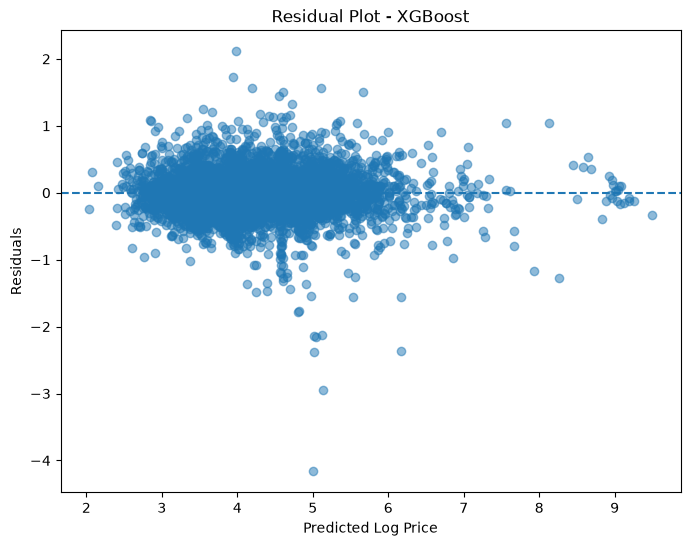

In [130]:
residuals = y_test - y_test_pred_xgb

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test_pred_xgb,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle='--'
)

plt.xlabel("Predicted Log Price")
plt.ylabel("Residuals")
plt.title("Residual Plot - XGBoost")

plt.show()

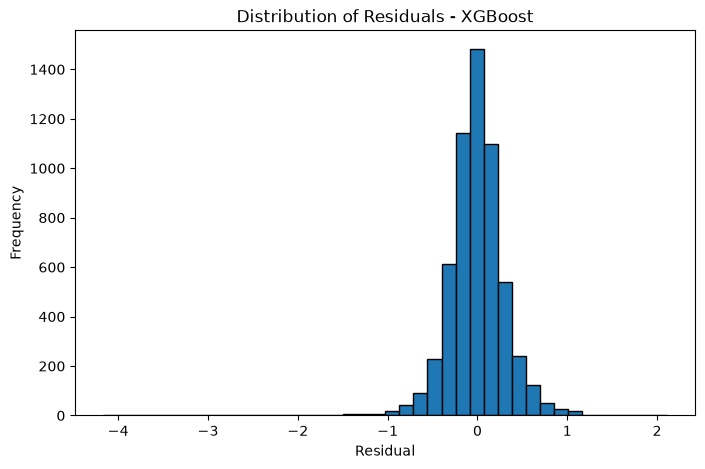

In [131]:
plt.figure(figsize=(8, 5))

plt.hist(
    residuals,
    bins=40,
    edgecolor='black'
)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals - XGBoost")

plt.show()

In [132]:
print("Mean Residual:", round(residuals.mean(), 4))
print("Median Residual:", round(residuals.median(), 4))
print("Residual Standard Deviation:", round(residuals.std(), 4))

Mean Residual: -0.0091
Median Residual: -0.0098
Residual Standard Deviation: 0.3189


## Residual Analysis

The residual analysis was performed for the final XGBoost model.

The residuals are largely distributed around zero, with a mean residual
of -0.0091 and a median residual of -0.0098. This indicates that the
model does not show a strong overall tendency to systematically
overpredict or underpredict property prices.

The residual distribution is concentrated around zero, although a few
extreme residuals are present. These observations are consistent with
the large prediction errors observed for some unusually high-priced
properties.

The residual standard deviation was 0.3189, which is close to the test
RMSE of 0.3190 on the log-transformed target.

Overall, the residual analysis indicates satisfactory model performance,
with most prediction errors concentrated around zero.

In [134]:
from sklearn.pipeline import Pipeline

final_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', xgb)
])

final_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['POSTED_BY','UNDER_CONSTRUCTION','RERA',...,'CITY','LONGITUDE','LATITUDE']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('scale', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of col

In [135]:
from sklearn.metrics import r2_score

pipeline_pred = final_pipeline.predict(X_test)

print(
    "Pipeline Test R2:",
    round(r2_score(y_test, pipeline_pred), 4)
)

Pipeline Test R2: 0.8671


In [136]:
import joblib

joblib.dump(final_pipeline, 'house_price_model.pkl')

print("Model pipeline saved successfully!")

Model pipeline saved successfully!


In [137]:
joblib.dump(list(common_cities), 'common_cities.pkl')

print("Common cities saved successfully!")

Common cities saved successfully!
